# Projeto 5 — CNN no CIFAR-10

Configuração do PyTorch e carregamento das 10 classes do CIFAR-10. Execute a célula de download manualmente quando desejar.

In [32]:
import torch
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Versão do PyTorch: {torch.__version__}")
print(f"Dispositivo selecionado: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(device)}")
else:
    print("GPU: indisponível para o PyTorch; usando CPU.")

Versão do PyTorch: 2.11.0+cu128
Dispositivo selecionado: cuda
GPU: NVIDIA GeForce RTX 3060


## Download e carregamento do CIFAR-10

A próxima célula baixa os dados para `data/` na primeira execução e reutiliza os arquivos nas execuções seguintes.

In [33]:
transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(root="data", train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root="data", train=False, download=True, transform=transform)

In [34]:
print(f"Imagens de treino: {len(train_dataset):,}")
print(f"Imagens de teste: {len(test_dataset):,}")
print(f"Classes ({len(train_dataset.classes)}): {', '.join(train_dataset.classes)}")

Imagens de treino: 50,000
Imagens de teste: 10,000
Classes (10): airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck


## Pré-processamento

Usamos seed 42 para separar 4.500 imagens de cada classe para treino e 500 para validação. O teste permanece separado. A normalização usa média e desvio 0,5 por canal, convertendo os pixels de [0, 1] para [-1, 1], sem estimar estatísticas na validação ou no teste.

In [35]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset

SEED = 42
BATCH_SIZE = 128
mean = (0.5, 0.5, 0.5)
std = (0.5, 0.5, 0.5)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
train_dataset.transform = transform
test_dataset.transform = transform

targets = torch.tensor(train_dataset.targets)
classes = train_dataset.classes
split_generator = torch.Generator().manual_seed(SEED)
train_indices, val_indices = [], []

for class_id in range(len(classes)):
    indices = torch.where(targets == class_id)[0]
    indices = indices[torch.randperm(len(indices), generator=split_generator)]
    val_indices.extend(indices[:500].tolist())
    train_indices.extend(indices[500:].tolist())

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)

assert len(train_subset) == 45_000 and len(val_subset) == 5_000
assert set(train_indices).isdisjoint(val_indices)
assert len(set(train_indices + val_indices)) == len(train_dataset)
print(f'Treino: {len(train_subset)} | Validação: {len(val_subset)} | Teste: {len(test_dataset)}')

Treino: 45000 | Validação: 5000 | Teste: 10000


### DataLoaders

Somente o treino é embaralhado. Usamos `num_workers=0` para facilitar a execução no Jupyter no Windows. As imagens são carregadas em lotes, sem enviar o dataset inteiro para a GPU.

In [36]:
loader_options = dict(batch_size=BATCH_SIZE, num_workers=0, pin_memory=device.type == 'cuda')
train_loader = DataLoader(train_subset, shuffle=True,generator=torch.Generator().manual_seed(SEED), **loader_options)
val_loader = DataLoader(val_subset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

print(f'Lotes — treino: {len(train_loader)}, validação: {len(val_loader)}, teste: {len(test_loader)}')

Lotes — treino: 352, validação: 40, teste: 79


### Imagens e distribuição das classes

Exibimos uma imagem de treino por classe, desfazendo a normalização apenas para visualização. A distribuição usa somente os rótulos.

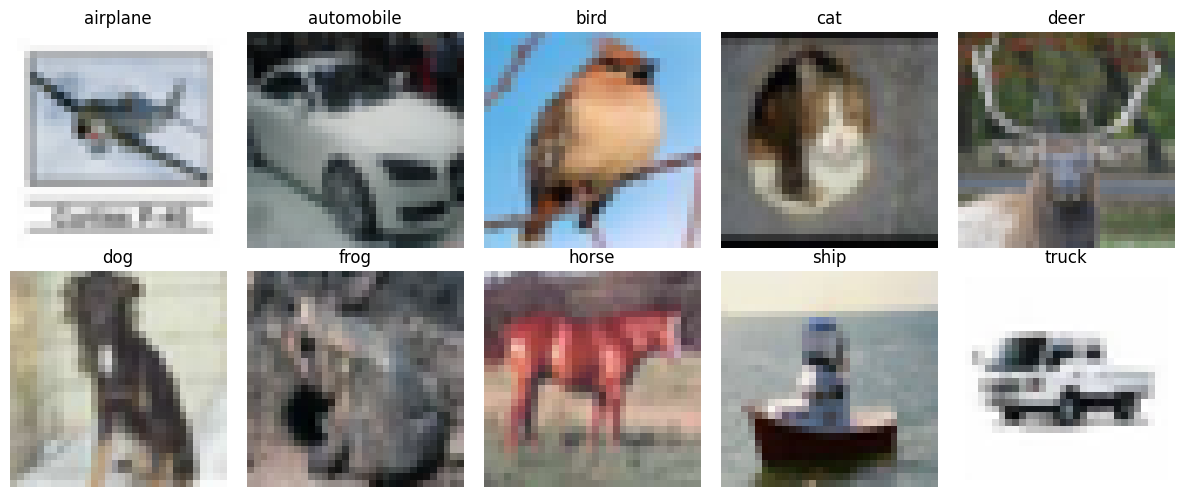

Classe           Treino  Validação    Teste
airplane           4500        500     1000
automobile         4500        500     1000
bird               4500        500     1000
cat                4500        500     1000
deer               4500        500     1000
dog                4500        500     1000
frog               4500        500     1000
horse              4500        500     1000
ship               4500        500     1000
truck              4500        500     1000


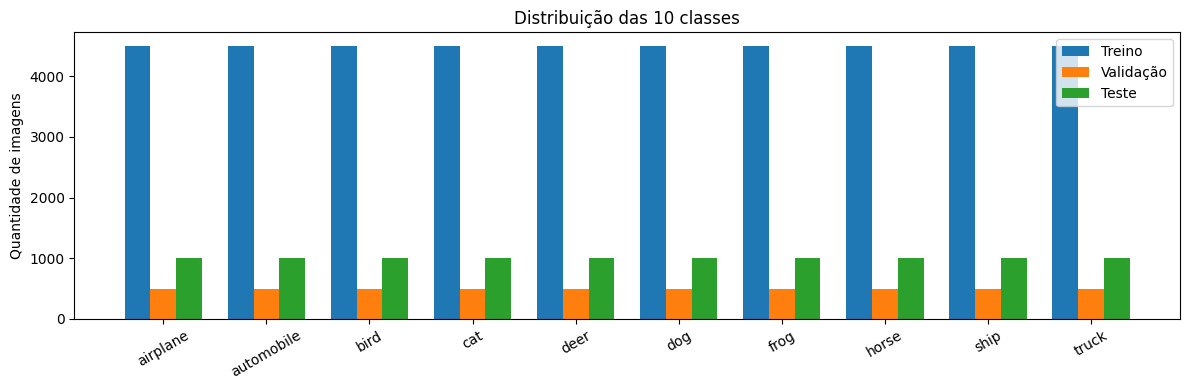

In [37]:
mean_tensor = torch.tensor(mean).view(3, 1, 1)
std_tensor = torch.tensor(std).view(3, 1, 1)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    index = next(i for i in train_indices if train_dataset.targets[i] == class_id)
    image, label = train_dataset[index]
    image = (image * std_tensor + mean_tensor).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(classes[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

class_counts = {
    'Treino': torch.bincount(targets[train_indices], minlength=10),
    'Validação': torch.bincount(targets[val_indices], minlength=10),
    'Teste': torch.bincount(torch.tensor(test_dataset.targets), minlength=10),
}
assert torch.all(class_counts['Treino'] == 4500)
assert torch.all(class_counts['Validação'] == 500)

print(f'{"Classe":<14} {"Treino":>8} {"Validação":>10} {"Teste":>8}')
for i, name in enumerate(classes):
    print(f'{name:<14} {class_counts["Treino"][i].item():>8} {class_counts["Validação"][i].item():>10} {class_counts["Teste"][i].item():>8}')

fig, ax = plt.subplots(figsize=(12, 4))
positions = torch.arange(len(classes)).numpy()
for offset, (name, counts) in enumerate(class_counts.items()):
    ax.bar(positions + (offset - 1) * 0.25, counts.numpy(), width=0.25, label=name)
ax.set_xticks(positions, classes, rotation=30)
ax.set_ylabel('Quantidade de imagens')
ax.set_title('Distribuição das 10 classes')
ax.legend()
plt.tight_layout()
plt.show()

## CNN configurável

Cada bloco usa Conv2d → BatchNorm opcional → ReLU → MaxPool2d → Dropout opcional. `num_blocks` aceita 2, 3 ou 4; `filters` define os filtros de cada bloco; `kernel_size` aceita 3 ou 5. `fc_layers` contém os tamanhos das camadas ocultas (pode ser vazio). `dropout` é aplicado após cada pooling e cada ReLU das camadas ocultas. A saída tem sempre 10 logits, sem Softmax.

A CNN-1 mantém dois blocos com 32 e 64 filtros, kernel 3, sem BatchNorm ou Dropout e uma camada oculta com 128 neurônios. A configuração fica em um dicionário, permitindo variar hiperparâmetros futuramente sem mudar a classe ou o treino.

In [38]:
from pathlib import Path
from torch import nn


class ConfigurableCNN(nn.Module):

    def __init__(self, num_blocks=2, filters=(32, 64), kernel_size=3,batch_norm=False, dropout=0.0, fc_layers=(128,)):

        super().__init__()
        filters = tuple(filters)
        fc_layers = tuple(fc_layers)
        if type(num_blocks) is not int or num_blocks not in (2, 3, 4):
            raise ValueError('num_blocks deve ser 2, 3 ou 4.')
        if len(filters) != num_blocks:
            raise ValueError('Informe uma quantidade de filtros para cada bloco.')
        if any(type(value) is not int or value <= 0 for value in filters):
            raise ValueError('Os filtros devem ser inteiros positivos.')
        if type(kernel_size) is not int or kernel_size not in (3, 5):
            raise ValueError('kernel_size deve ser 3 ou 5.')
        if type(batch_norm) is not bool:
            raise ValueError('batch_norm deve ser True ou False.')
        if not isinstance(dropout, (int, float)) or not 0 <= dropout < 1:
            raise ValueError('dropout deve estar entre 0 (inclusivo) e 1 (exclusivo).')
        if any(type(value) is not int or value <= 0 for value in fc_layers):
            raise ValueError('As camadas ocultas devem ter tamanhos inteiros positivos.')

        self.config = {
            'num_blocks': num_blocks,
            'filters': filters,
            'kernel_size': kernel_size,
            'batch_norm': batch_norm,
            'dropout': float(dropout),
            'fc_layers': fc_layers,
        }
        
        features = []
        in_channels = 3
        for out_channels in filters:
            features.append(nn.Conv2d(
                in_channels, out_channels, kernel_size=kernel_size,
                padding=kernel_size // 2,
            ))
            if batch_norm:
                features.append(nn.BatchNorm2d(out_channels))
            features.extend([nn.ReLU(), nn.MaxPool2d(kernel_size=2)])
            if dropout > 0:
                features.append(nn.Dropout2d(dropout))
            in_channels = out_channels
        self.features = nn.Sequential(*features)

        spatial_size = 32 // (2 ** num_blocks)
        in_features = filters[-1] * spatial_size * spatial_size
        classifier = [nn.Flatten()]
        for hidden_size in fc_layers:
            classifier.extend([nn.Linear(in_features, hidden_size), nn.ReLU()])
            if dropout > 0:
                classifier.append(nn.Dropout(dropout))
            in_features = hidden_size
        classifier.append(nn.Linear(in_features, 10))
        self.classifier = nn.Sequential(*classifier)

    def forward(self, x):
        return self.classifier(self.features(x))


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### Teste rápido da construção

Somente dois tensores RGB 32×32 em CPU, sem dados do CIFAR-10, gradientes ou treino. Verificamos a baseline e pequenas configurações de 2, 3 e 4 blocos. O teste preserva a seed global e não altera o modelo de treino.

In [39]:
def test_cnn_construction():
    with torch.random.fork_rng(devices=[]), torch.inference_mode():
        torch.manual_seed(42)
        images = torch.randn(2, 3, 32, 32)
        baseline = ConfigurableCNN().eval()
        assert baseline(images).shape == (2, 10)
        assert count_trainable_parameters(baseline) == 545_098
        assert not any(isinstance(m, (nn.BatchNorm2d, nn.Dropout, nn.Dropout2d))
                       for m in baseline.modules())
        assert [m.out_features for m in baseline.classifier
                if isinstance(m, nn.Linear)] == [128, 10]

        for blocks in (2, 3, 4):
            for kernel in (3, 5):
                for hidden_layers in ((), (16, 8)):
                    model = ConfigurableCNN(
                        num_blocks=blocks, filters=(4,) * blocks,
                        kernel_size=kernel, batch_norm=True,
                        dropout=0.2, fc_layers=hidden_layers,
                    ).eval()
                    output = model(images)
                    assert output.shape == (2, 10)
                    assert torch.isfinite(output).all()
                    assert sum(isinstance(m, nn.Conv2d) for m in model.modules()) == blocks
                    assert sum(isinstance(m, nn.BatchNorm2d) for m in model.modules()) == blocks
        print('Construção e passagem de dados: OK. Baseline: 545.098 parâmetros.')


test_cnn_construction()

Construção e passagem de dados: OK. Baseline: 545.098 parâmetros.


### Funções de treino e validação

As funções abaixo já recebem modelo, DataLoaders, loss, otimizador e dispositivo como argumentos e funcionam com qualquer configuração da CNN. Não precisam de mudanças. `fit` aceita um caminho de checkpoint por execução; use nomes diferentes ao comparar configurações no futuro.

As médias de loss e acurácia são ponderadas pela quantidade de imagens, incluindo o último lote. A validação desativa os gradientes. As acurácias ficam entre 0 e 1 no histórico.

In [40]:
def _run_epoch(model, loader, criterion, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total_samples = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)
            if not torch.isfinite(loss).item():
                raise ValueError('Loss não finita; verifique os dados e o modelo.')

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total_samples += batch_size

    if total_samples == 0:
        raise ValueError('O DataLoader está vazio.')
    return total_loss / total_samples, total_correct / total_samples


def train_one_epoch(model, loader, criterion, optimizer, device):
    return _run_epoch(model, loader, criterion, device, optimizer=optimizer)


def validate(model, loader, criterion, device):
    return _run_epoch(model, loader, criterion, device)

### Early Stopping e melhor modelo

Treinamos por até 30 épocas e paramos após 5 épocas consecutivas sem redução da loss de validação. Cada melhora salva o estado do modelo em `results/models/`. Ao terminar, os melhores pesos são restaurados. O conjunto de teste não participa desta etapa.

In [41]:
def fit(model, train_loader, val_loader, criterion, optimizer, device,max_epochs=30, patience=5,checkpoint_path='results/models/baseline_best.pt'):
    if max_epochs < 1 or patience < 1:
        raise ValueError('max_epochs e patience devem ser positivos.')
    if criterion.reduction != 'mean':
        raise ValueError('Use a loss com reduction="mean" para calcular as médias.')

    checkpoint_path = Path(checkpoint_path)
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    history = []
    best_val_loss = float('inf')
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = validate(model, val_loader, criterion, device)
        history.append({
            'epoch': epoch,
            'train_loss': train_loss,
            'train_acc': train_acc,
            'val_loss': val_loss,
            'val_acc': val_acc,
        })
        print(
            f'Época {epoch:02d}/{max_epochs} | '
            f'treino: loss={train_loss:.4f}, acc={train_acc:.2%} | '
            f'validação: loss={val_loss:.4f}, acc={val_acc:.2%}'
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0
            best_state = {
                name: tensor.detach().cpu().clone()
                for name, tensor in model.state_dict().items()
            }
            torch.save({
                'model_state_dict': best_state,
                'epoch': best_epoch,
                'val_loss': best_val_loss,
                'val_acc': val_acc,
                'trainable_parameters': count_trainable_parameters(model),
            }, checkpoint_path)
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f'Early Stopping: {patience} épocas sem melhora.')
                break

    model.load_state_dict(best_state)
    model.eval()
    print(f'Melhor época: {best_epoch} | loss de validação: {best_val_loss:.4f}')
    print(f'Modelo salvo em: {checkpoint_path}')
    return history

### Configuração e execução manual

Execute a próxima célula para criar o modelo e o Adam no dispositivo selecionado. Isso não inicia o treino. Para treinar, descomente a chamada da última célula. Para uma nova execução do zero, execute novamente a configuração abaixo.

In [42]:
torch.manual_seed(SEED)
if device.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)

MAX_EPOCHS = 30
PATIENCE = 5
LEARNING_RATE = 0.001

baseline_config = {
    'num_blocks': 2,
    'filters': (32, 64),
    'kernel_size': 3,
    'batch_norm': False,
    'dropout': 0.0,
    'fc_layers': (128,),
}

train_loader.generator.manual_seed(SEED)
baseline_model = ConfigurableCNN(**baseline_config).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)

print(baseline_model)
print(f'Parâmetros treináveis: {count_trainable_parameters(baseline_model):,}')
print(f'Dispositivo: {device} | Batch size: {train_loader.batch_size}')

ConfigurableCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parâmetros treináveis: 545,098
Dispositivo: cuda | Batch size: 128


In [43]:
baseline_history = fit(
    baseline_model, train_loader, val_loader, criterion, optimizer, device,
    max_epochs=MAX_EPOCHS, patience=PATIENCE,
    checkpoint_path='results/models/baseline_best.pt',
)

Época 01/30 | treino: loss=1.4691, acc=47.40% | validação: loss=1.2167, acc=56.78%
Época 02/30 | treino: loss=1.0921, acc=61.25% | validação: loss=1.0365, acc=64.00%
Época 03/30 | treino: loss=0.9307, acc=67.12% | validação: loss=0.9986, acc=65.02%
Época 04/30 | treino: loss=0.8244, acc=71.06% | validação: loss=0.9411, acc=67.34%
Época 05/30 | treino: loss=0.7396, acc=74.16% | validação: loss=0.8867, acc=69.06%
Época 06/30 | treino: loss=0.6633, acc=76.75% | validação: loss=0.8579, acc=70.66%
Época 07/30 | treino: loss=0.5928, acc=79.23% | validação: loss=0.8614, acc=71.24%
Época 08/30 | treino: loss=0.5240, acc=81.80% | validação: loss=0.8727, acc=71.36%
Época 09/30 | treino: loss=0.4544, acc=84.36% | validação: loss=0.9109, acc=72.00%
Época 10/30 | treino: loss=0.3949, acc=86.39% | validação: loss=0.9295, acc=72.36%
Época 11/30 | treino: loss=0.3310, acc=88.49% | validação: loss=1.0125, acc=70.36%
Early Stopping: 5 épocas sem melhora.
Melhor época: 6 | loss de validação: 0.8579
Model